# Encuesta Anual de Comercio (EAC) 2024 — DANE
### Proyecto DataXperience · Universidad EAN

**Integrantes:** Stiven Melo

**Fuente:** DANE — Encuesta Anual de Comercio (EAC), año de referencia 2024.
<https://www.dane.gov.co/index.php/estadisticas-por-tema/comercio-interno/encuesta-anual-de-comercio-eac>

**Unidad de observación:** la empresa comercial (microdato anonimizado).
**Unidad monetaria:** miles de pesos corrientes.

---

### Contenido

| | Sección |
|---|---|
| **1** | **Módulo 1 — Fundamentos y preparación de datos** |
| 1.1 | Configuración del entorno |
| 1.2 | Selección del conjunto de datos y justificación |
| 1.3 | Carga de los datos |
| 1.4 | Exploración de los datos |
| 1.5 | Diagnóstico de problemas |
| 1.6 | Limpieza y transformación |
| 1.7 | Resumen del dataset depurado |
| **2** | **Módulo 2** — _(pendiente)_ |
| **3** | **Módulo 3** — _(pendiente)_ |
| **4** | **Conclusiones** |

Cada celda de código lleva su número de apartado como primer comentario.

---
# 1. Módulo 1 — Fundamentos y preparación de datos

**Objetivo:** seleccionar, explorar y preparar un conjunto de datos relevante.

## 1.1 Configuración del entorno

Carga las librerías y resuelve las rutas. Se ejecuta una vez al abrir el cuaderno; si
reinicias el kernel, hay que volver a correrla.

### 1.1.1 Importar librerías y fijar opciones de visualización

Carga las cuatro librerías y ajusta cómo pandas imprime: con 63 columnas, sin
`display.max_columns = None` la mitad queda oculta tras puntos suspensivos.

> **Resultado:** pandas 3.1.0 · numpy 2.5.4 · seaborn 0.13.2

In [62]:
# 1.1.1 — Importar librerías y fijar opciones de visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option("display.float_format", "{:,.1f}".format)
sns.set_theme(style="whitegrid")

print("pandas:", pd.__version__, "|numpy:", np.__version__, "| seaborn:", sns.__version__)

pandas: 3.1.0 |numpy: 2.5.4 | seaborn: 0.13.2


### 1.1.2 Definir las rutas del proyecto

Define las rutas una sola vez y comprueba que los archivos existen antes de leerlos, para que
un error de ruta se vea aquí y no treinta líneas más abajo.

La primera línea hace que el cuaderno funcione igual en VS Code (ejecuta desde `notebook/`) y
en Colab (ejecuta desde la raíz).

> **Resultado:** los cuatro archivos localizados.

In [63]:
# 1.1.2 — Definir las rutas del proyecto
RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
CRUDOS = RAIZ / "datos" / "crudos"
PROCESADOS = RAIZ / "datos" / "procesados"

EAC_NACINAL = CRUDOS / "EAC_CIFRAS_2024_ANONIMIZADA_FINAL.csv"
EAC_DEPTO = CRUDOS / "EAC_CIFRAS_2024_ANONIMIZADA_DEP_FINAL.csv"
DIC_NACIONAL = CRUDOS / "EAC_Diccionario de datos_Nacional_2024.xlsx"
DIC_DEPTO = CRUDOS / "EAC_Diccionario de datos_Departamentos_2024.xlsx"

for ruta in [EAC_NACINAL, EAC_DEPTO, DIC_NACIONAL, DIC_DEPTO]:
    print("OK  " if ruta.exists() else "FALTA", ruta.name) 

OK   EAC_CIFRAS_2024_ANONIMIZADA_FINAL.csv
OK   EAC_CIFRAS_2024_ANONIMIZADA_DEP_FINAL.csv
OK   EAC_Diccionario de datos_Nacional_2024.xlsx
OK   EAC_Diccionario de datos_Departamentos_2024.xlsx


## 1.2 Selección del conjunto de datos y justificación

_(Redactar: por qué la EAC 2024, qué preguntas permite responder y cómo se relaciona con
nuestra formación. Apoyarse en la ficha metodológica del DANE.)_

## 1.3 Carga de los datos

Cargar el CSV **con los tipos correctos**. Si las cifras entran como texto, nada de lo que
viene después funciona. Primero se provoca el error a propósito, luego se resuelve.

### 1.3.1 Lectura ingenua: por qué este CSV no se deja leer

Esta celda **está hecha para fallar**: abre el archivo con los valores por defecto de
`read_csv` (separador `,`, decimal `.`, UTF-8).

El encabezado `V1;CORRELA_16;…` no tiene ni una coma, así que pandas cree que todo es una sola
columna. Pero las filas sí traen comas —son los decimales— y al encontrar más campos de los
esperados, aborta. El error es la evidencia del problema.

> **Resultado:** `ParserError: Expected 35 fields in line 3, saw 36`

In [64]:
# 1.3.1 — Lectura ingenua: ver qué pasa si se ignora el formato del archivo
try:
    crudo = pd.read_csv(EAC_NACINAL)
    print("Dimenciones: ", crudo.shape)
except Exception as e:
    print(f"{type(e).__name__}: {e}")

ParserError: Error tokenizing data. C error: Expected 35 fields in line 3, saw 36



### 1.3.2 Lectura correcta del microdato nacional

Tres ajustes que pandas no adivina: `sep=";"`, `decimal=","` y `encoding="latin-1"`. El más
olvidado es `decimal`: sin él, `7311674,8` se queda como texto y no se puede ni sumar.

`dtype` fuerza a texto `V1`, `CORRELA_16` y `CORRE_9` —nombres originales del archivo—. Son un
identificador y dos códigos: como números perderían ceros a la izquierda. En 1.3.3 pasan a
llamarse `empresa_id`, `actividad_16_cod` y `actividad_9_cod`.

> **Resultado:** 10.238 filas × 63 columnas — 59 `float64`, 3 `string`, 1 `int64`.

In [65]:
# 1.3.2 — Lectura correcta del microdato nacional
df = pd.read_csv(
    EAC_NACINAL,
    sep=";",
    decimal=",",
    encoding="latin-1",
    dtype= {"V1":"string", "CORRELA_16":"string", "CORRE_9":"string"}
)

print("Dimensiones:", df.shape)
print(df.dtypes.value_counts().to_dict())

Dimensiones: (10238, 63)
{dtype('float64'): 59, <StringDtype(storage='python', na_value=<NA>)>: 3, dtype('int64'): 1}


### 1.3.3 Renombrar las columnas a nombres legibles

`BRUTA`, `CIMREP`, `GASTOPNOP`, `PROMUJ`: nombres pensados para caber en ocho caracteres, no
para leerse. Se renombran aquí, nada más cargar, para que todo el resto del cuaderno trabaje
con nombres claros.

Tres reglas: `snake_case`, prefijo por familia (`gasto_*`, `personal_*`, `inventario_*`,
`remuneracion_*`) y sufijo `_cod` donde el valor sigue siendo un código.

No se pierde trazabilidad: la tabla que imprime la celda deja la equivalencia con los nombres
originales, y 1.4.2 le añade la descripción oficial.

> **Resultado:** 63 columnas renombradas.

In [66]:
# 1.3.3 — Renombrar las columnas a nombres legibles
NOMBRES = {
    # --- Identificación y clasificación ---
    "V1":             "empresa_id",
    "CORRELA_16":     "actividad_16_cod",
    "CORRE_9":        "actividad_9_cod",
    "IDOJ1":          "org_juridica_cod",
    "IDAIO":          "anio_inicio",

    # --- Agregados de la cuenta de producción ---
    "VENTA":          "ventas",
    "BRUTA":          "produccion_bruta",
    "CONSUI":         "consumo_intermedio",
    "AGREGA":         "valor_agregado",
    "CIMREP":         "pct_insumos_reparacion",

    # --- Gastos que componen el consumo intermedio ---
    "EMPAQUE":        "gasto_empaques",
    "HONORA":         "gasto_honorarios",
    "COMISION":       "gasto_comisiones",
    "ARRIENDO":       "gasto_arriendos",
    "SEGURO":         "gasto_seguros",
    "ASEO":           "gasto_aseo_vigilancia",
    "ENERGIA":        "gasto_energia",
    "GAS":            "gasto_gas_natural",
    "COMUNICA":       "gasto_comunicaciones",
    "PUBLICO":        "gasto_servicios_publicos",
    "FLETES":         "gasto_transporte",
    "PUBLICI":        "gasto_publicidad",
    "ADECUA":         "gasto_mantenimiento",
    "REGALA":         "gasto_regalias",
    "OUTSOURCING":    "gasto_outsourcing",
    "OTROS":          "gasto_otros",

    # --- Personal por tipo de vinculación ---
    "TOTPERSO":       "personal_total",
    "PERREMUN":       "personal_remunerado",
    "SOCIOS":         "socios_sin_remuneracion",
    "PERSONOM":       "personal_permanente",
    "DIRECTO":        "personal_temporal_directo",
    "AGENCIA":        "personal_agencias",
    "APRENDIZ":       "aprendices",

    # --- Personal desagregado por sexo ---
    "TOTMUJ":         "personal_mujeres",
    "TOTHOM":         "personal_hombres",
    "PROMUJ":         "socios_mujeres",
    "PROHOM":         "socios_hombres",
    "PERMUJ":         "permanente_mujeres",
    "PERHOM":         "permanente_hombres",
    "DIRMUJ":         "temporal_directo_mujeres",
    "DIRHOM":         "temporal_directo_hombres",
    "AGEMUJ":         "agencias_mujeres",
    "AGEHOM":         "agencias_hombres",
    "APRENMUJ":       "aprendices_mujeres",
    "APRENHOM":       "aprendices_hombres",

    # --- Remuneraciones ---
    "SUELDOS":        "sueldos",
    "PRESTAC":        "prestaciones",
    "SUEPLAN":        "sueldos_planta",
    "PREPLAN":        "prestaciones_planta",
    "REMPLAN":        "remuneracion_planta",
    "COTIZA":         "cotizaciones_patronales",
    "GASAGEN":        "gasto_personal_agencias",
    "REMTEMP":        "remuneracion_temporal",
    "TOTREM":         "remuneracion_total",

    # --- Inventarios ---
    "INVINI":         "inventario_inicial",
    "INVFIN":         "inventario_final",
    "INVPRO":         "inventario_promedio",
    "ROTACION":       "rotacion_inventarios",

    # --- Costos y gastos ---
    "CTO":            "costo_mercancia_vendida",
    "CTOINS":         "costo_mercancia_e_insumos",
    "GASTOS":         "costos_gastos_operacionales",
    "GASTOSNOP":      "gastos_no_operacionales",
    "GASTOPNOP":      "costos_gastos_totales",
}

if "empresa_id" not in df.columns:
    sin_mapear = [c for c in df.columns if c not in NOMBRES]
    assert not sin_mapear, f"Columnas sin nombre nuevo: {sin_mapear}"
    assert len(set(NOMBRES.values())) == len(NOMBRES), "Hay nombres nuevos repetidos"
    df = df.rename(columns=NOMBRES)

print(len(df.columns), "columnas:", list(df.columns)[:5], "...")
pd.DataFrame({"original": list(NOMBRES), "nuevo": list(NOMBRES.values())})

63 columnas: ['empresa_id', 'actividad_16_cod', 'actividad_9_cod', 'org_juridica_cod', 'anio_inicio'] ...


,original,nuevo
0,V1,empresa_id
1,CORRELA_16,actividad_16_cod
2,CORRE_9,actividad_9_cod
3,IDOJ1,org_juridica_cod
4,IDAIO,anio_inicio
...,...,...
58,CTO,costo_mercancia_vendida
59,CTOINS,costo_mercancia_e_insumos
60,GASTOS,costos_gastos_operacionales
61,GASTOSNOP,gastos_no_operacionales


### 1.3.4 Primer vistazo

Mira la columna `Non-Null Count` buscando cualquier valor distinto de 10238.

> **Resultado:** solo `org_juridica_cod` tiene 10.236. Ese es el único problema de nulos del
> archivo.

In [67]:
# 1.3.4 — Primer vistazo: dimensiones, tipos y primeras filas
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas")
df.info(show_counts = True)
df.head(3)

10,238 filas x 63 columnas
<class 'pandas.DataFrame'>
RangeIndex: 10238 entries, 0 to 10237
Data columns (total 63 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   empresa_id                   10238 non-null  string 
 1   actividad_16_cod             10238 non-null  string 
 2   actividad_9_cod              10238 non-null  string 
 3   org_juridica_cod             10236 non-null  float64
 4   anio_inicio                  10238 non-null  int64  
 5   pct_insumos_reparacion       10238 non-null  float64
 6   produccion_bruta             10238 non-null  float64
 7   consumo_intermedio           10238 non-null  float64
 8   gasto_gas_natural            10238 non-null  float64
 9   gasto_empaques               10238 non-null  float64
 10  gasto_honorarios             10238 non-null  float64
 11  gasto_comisiones             10238 non-null  float64
 12  gasto_arriendos              10238 non-null  float64
 13  

,empresa_id,actividad_16_cod,actividad_9_cod,org_juridica_cod,anio_inicio,pct_insumos_reparacion,produccion_bruta,consumo_intermedio,gasto_gas_natural,gasto_empaques,gasto_honorarios,gasto_comisiones,gasto_arriendos,gasto_seguros,gasto_aseo_vigilancia,gasto_energia,gasto_comunicaciones,gasto_servicios_publicos,gasto_transporte,gasto_publicidad,gasto_mantenimiento,gasto_regalias,gasto_outsourcing,gasto_otros,sueldos,prestaciones,ventas,valor_agregado,personal_remunerado,socios_sin_remuneracion,personal_permanente,personal_temporal_directo,personal_agencias,aprendices,personal_total,socios_mujeres,socios_hombres,permanente_mujeres,permanente_hombres,temporal_directo_mujeres,temporal_directo_hombres,agencias_mujeres,agencias_hombres,aprendices_mujeres,aprendices_hombres,personal_mujeres,personal_hombres,sueldos_planta,prestaciones_planta,remuneracion_planta,cotizaciones_patronales,gasto_personal_agencias,remuneracion_temporal,remuneracion_total,inventario_inicial,inventario_final,rotacion_inventarios,inventario_promedio,costo_mercancia_vendida,costo_mercancia_e_insumos,costos_gastos_operacionales,gastos_no_operacionales,costos_gastos_totales
0,1032166,4711-472,471-472,7.0,2010,0.0,"7,311,674.8","3,529,458.6",0.0,"4,916.4","47,522.8",0.0,"2,940,572.4","5,824.8","9,930.4","76,754.4","20,096.8","21,118.4","103,345.2","55,682.0","38,589.2",0.0,0.0,"205,105.8","511,022.8","211,921.2","12,994,085.2","3,782,216.2",17.2,0.0,17.2,0.0,0.0,0.8,18.0,0.0,0.0,8.0,9.2,0.0,0.0,0.0,0.0,0.0,0.8,8.0,10.0,"499,074.0","113,905.6","612,979.6","84,372.4",0.0,0.0,"697,352.0","2,439,072.4","2,343,757.6","5,682,410.4","2,391,415.0","5,682,410.4","5,682,410.4","9,510,285.6","2,617,039.6","12,914,970.4"
1,1032165,4711-472,471-472,7.0,2010,0.0,"10,967,512.2","5,294,187.9",0.0,"7,374.6","71,284.2",0.0,"4,410,858.6","8,737.2","14,895.6","115,131.6","30,145.2","31,677.6","155,017.8","83,523.0","57,883.8",0.0,0.0,"307,658.7","766,534.2","317,881.8","19,491,127.8","5,673,324.3",25.8,0.0,25.8,0.0,0.0,1.2,27.0,0.0,0.0,12.0,13.8,0.0,0.0,0.0,0.0,0.0,1.2,12.0,15.0,"748,611.0","170,858.4","919,469.4","126,558.6",0.0,0.0,"1,046,028.0","3,658,608.6","3,515,636.4","8,523,615.6","3,587,122.5","8,523,615.6","8,523,615.6","14,265,428.4","3,925,559.4","19,372,455.6"
2,3412456,4741-4742,474 - 475,4.0,2006,0.0,"5,319,666.4","343,462.6",0.4,0.0,"193,882.0",0.0,"77,229.2","1,883.2",536.8,"5,102.4","53,522.4",246.4,"1,949.6",0.0,"8,246.0",0.0,0.0,864.2,"1,335,057.2","634,450.4","5,813,187.2","4,976,203.8",15.2,0.0,15.2,0.0,0.0,0.0,15.2,0.0,0.0,6.4,8.8,0.0,0.0,0.0,0.0,0.0,0.0,6.4,8.8,"1,335,057.2","329,768.0","1,664,825.2","252,322.2",0.0,0.0,"1,917,147.4","280,636.8","120,587.2","493,520.8","200,612.0","493,520.8","493,520.8","837,868.4","15,072.0","2,824,236.4"


## 1.4 Exploración de los datos

Entender los datos **antes** de tocarlos: qué mide cada variable, qué forma tienen las
distribuciones y qué categorías dominan. Cubre los puntos «identifica tipos de variables» y
«distribuciones iniciales» del enunciado.

### 1.4.1 Leer el diccionario de datos oficial desde el .xlsx

Trae las descripciones oficiales al cuaderno en lugar de tenerlas en un Excel aparte.

Dos arreglos: el diccionario llama `CORRELA_9` a la variable que el archivo de datos llama
`CORRE_9` —primer problema detectado—, y los nombres se traducen a los nuevos de 1.3.3 para
poder cruzarlos con las columnas ya renombradas.

> **Resultado:** 63 variables documentadas de 63.

In [68]:
# 1.4.1 — Leer el diccionario de datos oficial desde el .xlsx
dic = pd.read_excel(DIC_NACIONAL, sheet_name=0, header=8)
dic.columns = ["variable", "descripcion"]
dic = dic.dropna()
dic["descripcion"] = dic["descripcion"].str.strip()

# El diccionario del DANE llama CORRELA_9 a la variable que el archivo de datos llama CORRE_9
dic["original"] = dic["variable"].str.strip().replace({"CORRELA_9": "CORRE_9"})

# Traducir los nombres originales a los nombres nuevos definidos en 1.3.3
dic["variable"] = dic["original"].replace(NOMBRES)
dic = dic[dic["variable"].isin(df.columns)]

print(len(dic), "variables documentadas de", df.shape[1])
dic.head()

63 variables documentadas de 63


,variable,descripcion,original
0,empresa_id,Consecutivo de identificación de la empresa,V1
1,actividad_16_cod,Correlativa a nivel de 16 dominios de estudio ...,CORRELA_16
2,actividad_9_cod,Correlativa a nivel de 9 dominios de estudio s...,CORRE_9
3,org_juridica_cod,"Tipo de organización jurídica - Ver hoja ""Orga...",IDOJ1
4,anio_inicio,Año de inicio operaciones,IDAIO


### 1.4.2 Tabla resumen de las 63 variables

Tipo, nulos, valores distintos, rango y descripción de cada variable en una sola tabla. Es
evidencia del enunciado y la base del diccionario que falta en `datos/README.md`.

Clasificación por naturaleza, que es el trabajo que la tabla permite hacer (en pandas todas
llegan como números):

| Tipo | Variables |
|---|---|
| Identificador | `empresa_id` — no se analiza ni se promedia |
| Categóricas nominales | `actividad_16_cod`, `actividad_9_cod`, `org_juridica_cod` |
| Temporal discreta | `anio_inicio` |
| Razón | `pct_insumos_reparacion` — un porcentaje, no un monto |
| Cuantitativas continuas | ~40 columnas monetarias, en miles de pesos |
| Cuantitativas de conteo | 18 columnas de personal, por sexo y vinculación |

> **Resultado:** 63 filas, ninguna sin descripción.

In [69]:
# 1.4.2 — Tabla resumen de las 63 variables
resumen = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "unicos": df.nunique(),
    "minimo": df.min(numeric_only=True),
    "maximo": df.max(numeric_only=True)
}).join(dic.set_index("variable")[["original", "descripcion"]])

resumen.index.name = "variable"
resumen

,dtype,nulos,unicos,minimo,maximo,original,descripcion
variable,,,,,,,
actividad_16_cod,string,0,16,NaN,NaN,CORRELA_16,Correlativa a nivel de 16 dominios de estudio ...
actividad_9_cod,string,0,9,NaN,NaN,CORRE_9,Correlativa a nivel de 9 dominios de estudio s...
agencias_hombres,float64,0,132,0.0,"2,625.7",AGEHOM,Personal temporal cont a través de agencias - ...
agencias_mujeres,float64,0,125,0.0,"1,817.0",AGEMUJ,Personal temporal cont a través de agencias - ...
anio_inicio,int64,0,93,"1,918.0","2,024.0",IDAIO,Año de inicio operaciones
...,...,...,...,...,...,...,...
sueldos_planta,float64,0,8575,0.0,"401,060,883.0",SUEPLAN,Sueldos Planta (miles de pesos)
temporal_directo_hombres,float64,0,201,0.0,"1,149.7",DIRHOM,Personal temporal directo-Hombres
temporal_directo_mujeres,float64,0,185,0.0,"1,704.0",DIRMUJ,Personal temporal directo-Mujeres


### 1.4.3 Estadísticos descriptivos

Lo que importa es la distancia entre la mediana (`50%`), la media y el máximo.

La media está muy por encima de la mediana: **unas pocas empresas gigantes la arrastran, así
que no representa al sector**.

> **Resultado:** mediana de `ventas` muy por debajo de su media.

In [70]:
# 1.4.3 — Estadísticos descriptivos de las variables numéricas
num = df.select_dtypes(include=np.number)
num.describe().T[["count","mean","50%","max"]].round(1)

,count,mean,50%,max
org_juridica_cod,"10,236.0",12.2,14.0,99.0
anio_inicio,"10,238.0","2,001.1","2,003.0","2,024.0"
pct_insumos_reparacion,"10,238.0","203,947.1",0.0,"141,286,688.0"
produccion_bruta,"10,238.0","11,856,157.6","2,629,689.5","2,007,621,605.0"
consumo_intermedio,"10,238.0","4,327,635.2","733,873.0","969,638,853.5"
gasto_gas_natural,"10,238.0","3,791.2",0.0,"3,666,108.0"
gasto_empaques,"10,238.0","69,766.2",0.0,"20,054,711.0"
gasto_honorarios,"10,238.0","392,689.3","67,645.5","96,767,043.0"
gasto_comisiones,"10,238.0","107,253.4",0.0,"69,193,473.0"
gasto_arriendos,"10,238.0","593,037.1","97,615.0","165,235,652.0"


### 1.4.4 Frecuencias de las variables categóricas

Busca categorías dominantes, que sesgan los promedios, y categorías diminutas, que no soportan
análisis. `dropna=False` hace que los nulos salgan como una categoría más.

> **Resultado:**
> - `org_juridica_cod = 14` (Sociedad por Acciones Simplificada): 7.224 de 10.238, el **71 %**
> - Solo aparecen 12 de los 15 códigos del diccionario
> - `org_juridica_cod = 6` tiene 2 empresas, y hay 2 filas con valor faltante
>
> Dice 12 y no 13 porque `nunique()` no cuenta los nulos, aunque `value_counts(dropna=False)`
> sí los liste.

In [71]:
# 1.4.4 — Frecuencias de las variables categóricas
for col in ["actividad_16_cod","actividad_9_cod","org_juridica_cod"]:
    print(f"\n--- {col}({df[col].nunique()} categorias) ---")
    print(df[col].value_counts(dropna=False))


--- actividad_16_cod(16 categorias) ---
actividad_16_cod
466          1929
462          1482
464          1398
465          1145
473           949
4711-472      827
453           478
4771-4751     328
4759-4761     295
4773          280
4741-4742     271
4752          266
454           215
451           201
4772          137
4719           37
Name: count, dtype: Int64

--- actividad_9_cod(9 categorias) ---
actividad_9_cod
464-465      2543
466-469      1929
462-463      1482
476 - 477    1040
473           949
471-472       864
453-454       693
474 - 475     537
451           201
Name: count, dtype: Int64

--- org_juridica_cod(12 categorias) ---
org_juridica_cod
14.0    7224
11.0    1080
5.0      878
4.0      763
12.0      70
2.0       65
7.0       44
13.0      38
3.0       29
9.0       22
99.0      21
6.0        2
NaN        2
Name: count, dtype: int64


### 1.4.5 Distribución de ventas, escala original y logarítmica

El panel izquierdo sale ilegible a propósito: con esta asimetría todas las empresas se
amontonan en una sola barra. El derecho aplica logaritmo, que comprime las colas y revela la
forma real — es la transformación estándar para variables económicas.

Hay que filtrar los ceros antes, porque el logaritmo de cero no existe. Esos ceros son el
hallazgo de 1.5.3.

> **Resultado:** izquierda con una única barra en el origen; derecha, una campana.

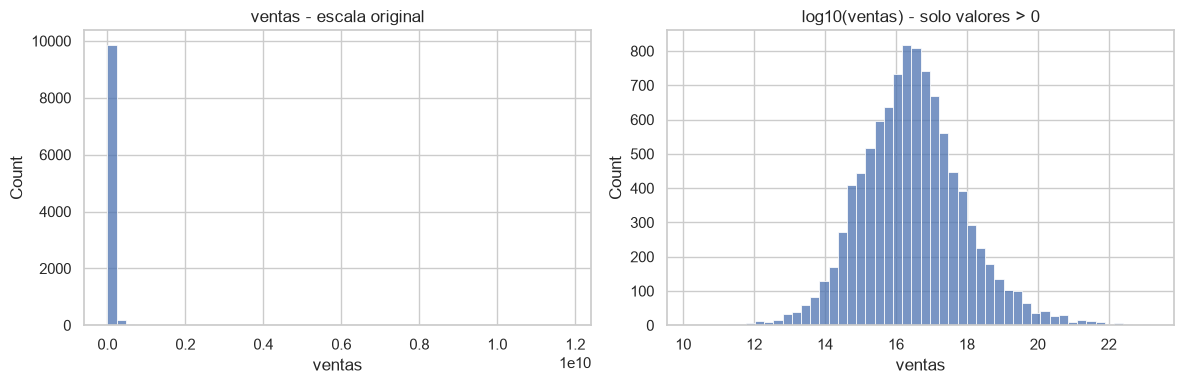

In [72]:
# 1.4.5 — Distribución de ventas: escala original frente a escala logarítmica
fig, axes = plt.subplots(1,2, figsize = (12,4))

sns.histplot(df["ventas"], bins=50, ax=axes[0])
axes[0].set_title("ventas - escala original")

sns.histplot(np.log1p(df.loc[df["ventas"] > 0 , "ventas"]), bins=50, ax=axes[1])
axes[1].set_title("log10(ventas) - solo valores > 0")

plt.tight_layout()
plt.show()

### 1.4.6 Año de inicio de operaciones

Control de calidad de cualquier campo de fecha: buscar valores imposibles — año 0, años
futuros, centinelas tipo 9999.

> **Resultado:** rango 1918–2024. Plausible: **esta variable no necesita corrección**, y
> confirmarlo también es un hallazgo.

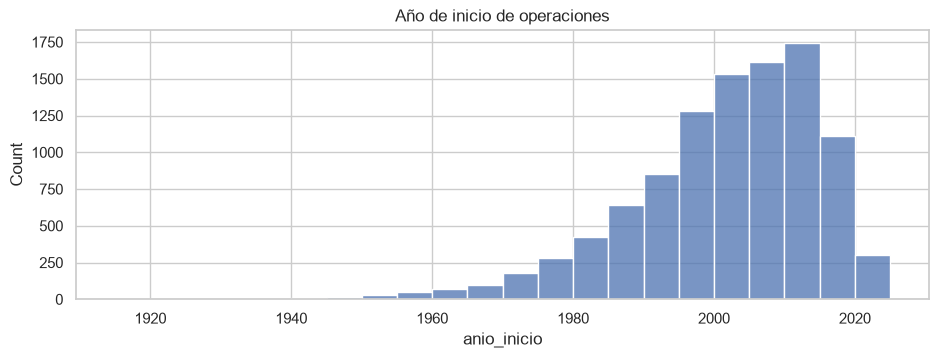

count   10,238.0
mean     2,001.1
std         13.5
min      1,918.0
25%      1,994.0
50%      2,003.0
75%      2,011.0
max      2,024.0
Name: anio_inicio, dtype: float64

In [73]:
# 1.4.6 — Distribución del año de inicio de operaciones
fig, ax = plt.subplots(figsize=(11, 3.5))
sns.histplot(df["anio_inicio"], bins=list(range(1915, 2030, 5)), ax=ax)
ax.set_title("Año de inicio de operaciones")
plt.show()

df["anio_inicio"].describe()

### 1.4.7 Personal total por dominio de actividad

Primer cruce de una variable numérica con una categórica. Las cajas van ordenadas por
frecuencia, no alfabéticamente, y el eje en escala logarítmica por lo mismo que en 1.4.5.

> **Resultado:** medianas parecidas entre dominios, pero colas derechas muy largas. Los puntos
> sueltos de la derecha son las grandes superficies.

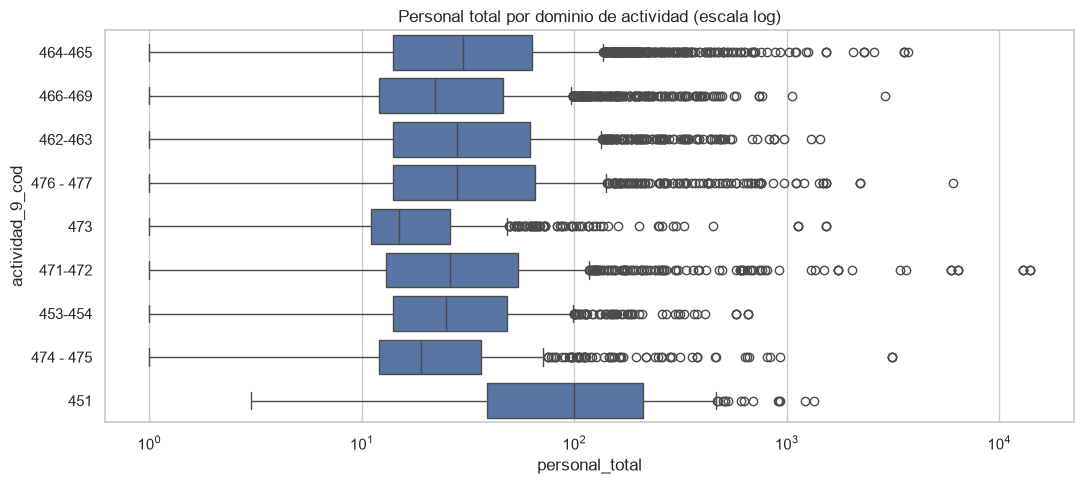

In [74]:
# 1.4.7 — Personal total por dominio de actividad
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df[df["personal_total"] > 0], x="personal_total", y="actividad_9_cod", ax=ax,
            order=df["actividad_9_cod"].value_counts().index)
ax.set_xscale("log")
ax.set_title("Personal total por dominio de actividad (escala log)")
plt.tight_layout()
plt.show()

## 1.5 Diagnóstico de problemas

Buscar problemas de forma sistemática, no por intuición. Ocho celdas, ocho preguntas: ¿faltan
datos? ¿hay repetidos? ¿hay registros vacíos? ¿hay valores imposibles? ¿cuadran las cuentas?
¿están bien escritos los códigos? ¿existen todos en el catálogo? ¿se pueden cruzar los dos
archivos?

Cada salida alimenta una fila de la síntesis de 1.5.9.

### 1.5.1 Valores faltantes

Nulos en número y en porcentaje, porque la decisión depende de la proporción. Solo se muestran
las columnas afectadas.

> **Resultado:** `org_juridica_cod` con 2 nulos, el 0,02 % del archivo.

In [75]:
# 1.5.1 — Valores faltantes
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "pct":   (df.isna().mean() * 100).round(3),
})
nulos[nulos["nulos"] > 0]

,nulos,pct
org_juridica_cod,2,0.0


### 1.5.2 Duplicados

Dos revisiones distintas: filas repetidas enteras, e identificador repetido con datos
diferentes. La segunda sería un error de carga grave.

> **Resultado:** 0 y 0, con 10.238 identificadores únicos sobre 10.238 filas. `empresa_id` es
> una clave primaria válida.


In [76]:
# 1.5.2 — Duplicados: filas completas e identificador
print("Filas identicas:", df.duplicated().sum())
print("empresa_id repetidos   :", df["empresa_id"].duplicated().sum())
print("empresa_id unicos      :", df["empresa_id"].nunique(), "de", len(df))

Filas identicas: 0
empresa_id repetidos   : 0
empresa_id unicos      : 10238 de 10238


### 1.5.3 Registros sin actividad económica

Busca empresas con **todas** las cifras en cero. Es el hallazgo más relevante del módulo.

La clave está en `.drop(["org_juridica_cod", "anio_inicio"])`: son numéricas pero no son
cifras —un código y un año—. Si se dejan dentro, la condición no se cumple nunca y el problema
queda invisible.

Son empresas del marco muestral que no operaron en 2024. No son errores, pero distorsionan
cualquier promedio del sector.

> **Resultado:** 329 registros, el 3,2 % del archivo.

In [77]:
# 1.5.3 — Registros sin actividad económica
cifras = df.select_dtypes(include=np.number).columns.drop(["org_juridica_cod", "anio_inicio"])
sin_actividad = (df[cifras] == 0).all(axis=1)

print("Registros con TODAS las cifras en cero:", sin_actividad.sum())
df.loc[sin_actividad, ["empresa_id", "actividad_16_cod", "anio_inicio", "ventas", "personal_total"]].head()

Registros con TODAS las cifras en cero: 329


,empresa_id,actividad_16_cod,anio_inicio,ventas,personal_total
28,1892140,466,2020,0.0,0.0
96,1892066,466,2018,0.0,0.0
119,1892039,466,2014,0.0,0.0
209,1891943,466,2015,0.0,0.0
216,1891935,465,2015,0.0,0.0


### 1.5.4 Valores negativos

La pregunta no es «¿lo elimino?» sino **«¿puede esto ser negativo en la realidad?»**.

Aquí sí: si el costo de mercancía supera las ventas, la producción bruta y el valor agregado
salen negativos. Son pérdidas reales, no errores de captura.

> **Resultado:** `valor_agregado` con 151 y `produccion_bruta` con 34. Ninguna otra columna.

In [78]:
# 1.5.4 — Valores negativos en variables monetarias
negativos = (df[cifras] < 0).sum()
negativos[negativos > 0]

produccion_bruta     34
valor_agregado      151
dtype: int64

### 1.5.5 Verificación de las identidades contables

El diccionario define relaciones aritméticas entre variables. Comprobarlas audita la
consistencia interna del archivo.

Se usa `np.isclose` y nunca `==`: con decimales en binario, `0.1 + 0.2 != 0.3`.

> **Resultado:** ambas se cumplen en el **100 %** de las filas. Los ceros y negativos
> encontrados son datos reales, no corrupción.

In [79]:
# 1.5.5 — Verificación de las identidades contables del diccionario
id1 = np.isclose(df["produccion_bruta"] - df["consumo_intermedio"], df["valor_agregado"])
id2 = np.isclose(df["personal_mujeres"] + df["personal_hombres"], df["personal_total"])

print(f"produccion_bruta - consumo_intermedio = valor_agregado    -> {id1.mean()*100:.2f} % de las filas")
print(f"personal_mujeres + personal_hombres = personal_total -> {id2.mean()*100:.2f} % de las filas")

produccion_bruta - consumo_intermedio = valor_agregado    -> 100.00 % de las filas
personal_mujeres + personal_hombres = personal_total -> 100.00 % de las filas


### 1.5.6 Inconsistencias de formato y conteos decimales

`repr()` muestra los valores entre comillas y así se ven los espacios: `'474 - 475'` y
`'474-475'` parecen iguales en pantalla, pero son dos categorías distintas.

Los decimales en el personal no son un error del archivo: es la perturbación que el DANE
aplica para anonimizar. Si decides redondear, ten en cuenta que puedes romper la identidad
verificada en 1.5.5.

> **Resultado:** `'474 - 475'` y `'476 - 477'` con espacios, los otros siete sin ellos. 108
> filas con personal decimal.

In [80]:
# 1.5.6 — Inconsistencias de formato y conteos de personal con decimales

print("Valores de actividad_9_cod:", [repr(v) for v in sorted(df["actividad_9_cod"].unique())])
print("Filas con personal_total decimal:", (df["personal_total"] % 1 != 0).sum())

df.loc[df["personal_total"] % 1 != 0, ["empresa_id", "personal_mujeres", "personal_hombres", "personal_total"]].head()

Valores de actividad_9_cod: ["'451'", "'453-454'", "'462-463'", "'464-465'", "'466-469'", "'471-472'", "'473'", "'474 - 475'", "'476 - 477'"]
Filas con personal_total decimal: 108


,empresa_id,personal_mujeres,personal_hombres,personal_total
2,3412456,6.4,8.8,15.2
3,3412455,9.6,13.2,22.8
4,3393256,3.6,8.8,12.4
5,3393255,5.4,13.2,18.6
6,3381856,4.0,2.8,6.8


### 1.5.7 Códigos que no existen en el diccionario

Busca códigos usados en los datos que el catálogo oficial no define — huérfanos contra la tabla
de catálogo.

Se accede por posición porque la hoja tiene encabezados combinados y nombres repetidos. Hay que
normalizar los espacios antes de comparar, o salen falsos huérfanos por el problema de 1.5.6.

> **Resultado:** el código `4771-4751` está en el archivo pero **no en el diccionario del
> DANE**, y afecta a 328 filas (3,2 %). Los 9 dominios están todos documentados.

In [81]:
# 1.5.7 — Códigos presentes en el CSV que no existen en el diccionario
ciiu = pd.read_excel(DIC_NACIONAL, sheet_name=2, header=8)

cod16 = set(ciiu.iloc[:, 4].dropna().astype(str))
cod9  = set(ciiu.iloc[:, 6].dropna().astype(str).str.replace(" ", "", regex=False))

huerfanos16 = set(df["actividad_16_cod"]) - cod16
huerfanos9  = set(df["actividad_9_cod"].str.replace(" ", "", regex=False)) - cod9

print("actividad_16_cod sin descripcion:", huerfanos16)
print("actividad_9_cod sin descripcion   :", huerfanos9)
print("Filas afectadas:", df["actividad_16_cod"].isin(huerfanos16).sum())

actividad_16_cod sin descripcion: {'4771-4751'}
actividad_9_cod sin descripcion   : set()
Filas afectadas: 328


### 1.5.8 ¿Cruzan el archivo nacional y el departamental?

Hay que responder esto **antes** de planear cualquier análisis geográfico: define el alcance
del proyecto.

`DEPTO` se lee como texto porque sus códigos son `01`…`10`, y como número `01` pasa a `1` y
deja de cruzar con el diccionario.

> **Resultado:** 14.995 filas pero 9.902 empresas distintas — es **formato largo**, una fila
> por empresa y departamento.
>
> Solo 365 identificadores coinciden con el nacional, y por azar: la anonimización renumeró
> cada archivo por separado. **No se pueden unir con `merge`.** Se trabaja el nacional como
> dataset principal.

In [82]:
# 1.5.8 — El archivo departamental: comprobar si cruza con el nacional
dep = pd.read_csv(EAC_DEPTO, sep=";", decimal=",", encoding="latin-1",
                  dtype={"V1": "string", "DEPTO": "string", "CORRELA_9": "string"})

dep = dep.rename(columns={"V1": "empresa_id", "DEPTO": "departamento_cod",
                          "CORRELA_9": "actividad_9_cod", "VENTA": "ventas",
                          "Personal": "personal_total"})

print("Departamental:", dep.shape, "|", dep["empresa_id"].nunique(), "empresas distintas")
print("Compartidos con el nacional:", len(set(dep["empresa_id"]) & set(df["empresa_id"])))
dep.head()

Departamental: (14995, 5) | 9902 empresas distintas
Compartidos con el nacional: 365


,empresa_id,departamento_cod,actividad_9_cod,ventas,personal_total
0,994577,10,471-472,"4,212,573.0",8
1,994579,10,462-463,"5,421,934.0",12
2,994581,10,466-469,"13,437,761.0",9
3,994582,10,473,"11,727,195.0",18
4,994583,10,464-465,"12,834,252.0",10


### 1.5.9 Síntesis de los problemas detectados

Hallazgos de 1.5.1 a 1.5.8. La última columna la completas tú con la decisión del apartado
1.6 y su razón.

| # | Problema detectado | Columnas afectadas | Celda | Magnitud | Decisión tomada y por qué |
|---|---|---|---|---|---|
| 1 | Formato no estándar: separador `;`, coma decimal y saltos de línea `\r` | todo el archivo | 1.3.1 | — |  |
| 2 | Desajuste de nombre entre el CSV y el diccionario (`CORRE_9` / `CORRELA_9`) | `actividad_9_cod` | 1.4.1 | 1 columna |  |
| 3 | Valores faltantes | `org_juridica_cod` | 1.5.1 | 2 filas (0,02 %) |  |
| 4 | Registros sin actividad económica: todas las cifras en cero | todas las numéricas | 1.5.3 | 329 filas (3,2 %) |  |
| 5 | Valores negativos | `valor_agregado`, `produccion_bruta` | 1.5.4 | 185 filas |  |
| 6 | Espacios inconsistentes dentro de los códigos | `actividad_9_cod` | 1.5.6 | 2 de 9 categorías |  |
| 7 | Conteos de personal con decimales (perturbación anonimizadora) | las 18 de personal | 1.5.6 | 108 filas |  |
| 8 | Código `4771-4751` ausente del diccionario oficial | `actividad_16_cod` | 1.5.7 | 328 filas (3,2 %) |  |
| 9 | Claves incompatibles entre el archivo nacional y el departamental | `empresa_id` | 1.5.8 | 365 de 9.902 |  |
| 10 | Asimetría extrema: la media no representa al sector | todas las monetarias | 1.4.3, 1.4.5 | — |  |

**Verificaciones sin hallazgo** (también son resultado y conviene dejarlas escritas): no hay
filas duplicadas ni identificadores repetidos (1.5.2), no hay años fuera de rango (1.4.6), y las dos
identidades contables del diccionario se cumplen en el 100 % de los registros (1.5.5).

## 1.6 Limpieza y transformación

Actuar sobre cada problema del diagnóstico, sin tocar nunca los datos crudos.

Lo que cuenta aquí no es el código sino **la justificación de cada decisión**: qué se elimina,
qué se conserva, qué se imputa y con qué criterio.

### 1.6.1 Copia de trabajo

Separa el original de lo que se va a modificar, para poder comparar antes y después en 1.7.1.
`datos/crudos/` no se modifica nunca: es la fuente de verdad que permite reproducir todo desde
cero.

In [83]:
# 1.6.1 — Crear la copia de trabajo
df_limpio = df.copy()
print("Punto de partida:", df_limpio.shape)

Punto de partida: (10238, 63)


### 1.6.2 Eliminar los registros sin actividad económica

Aplica la decisión sobre las 329 empresas de 1.5.3. El operador `~` invierte la máscara: se
conserva lo contrario de «sin actividad».

> **Resultado:** 329 registros eliminados — de 10.238 a 9.909 filas.

**Decisión y justificación:**

_(Redactar: por qué se eliminan en lugar de conservarlas marcadas con una columna booleana.
Mencionar el efecto que tendrían sobre los promedios del sector y qué se pierde al excluirlas.)_

In [84]:
# 1.6.2 — Eliminar los registros sin actividad económica
antes = len(df_limpio)
df_limpio = df_limpio.loc[~sin_actividad].copy()

print(f"Eliminados {antes - len(df_limpio)} registros sin actividad economica")
print("Dataset:", df_limpio.shape)

Eliminados 329 registros sin actividad economica
Dataset: (9909, 63)


### 1.6.3 Tratar los valores faltantes de org_juridica_cod

No se imputa con la moda: el 71 % ya es «Sociedad por Acciones Simplificada» y meter dos
empresas más ahí sería inventar información. Se usa `-1` como centinela, un código que no
existe en el diccionario, y en 1.6.4 se etiqueta «Sin dato».

`astype(int)` solo funciona después del `fillna`, porque una columna con nulos no se convierte
a entero. Por eso `org_juridica_cod` llegó como `float64`.

> **Resultado:** 2 nulos antes, 0 después.

**Decisión y justificación:**

_(Redactar: por qué declarar el dato como ausente es preferible a imputarlo, dado que
representa el 0,02 % de los registros.)_

In [85]:
# 1.6.3 — Tratar los valores faltantes de org_juridica_cod
print("Nulos en org_juridica_cod antes:", df_limpio["org_juridica_cod"].isna().sum())

df_limpio["org_juridica_cod"] = df_limpio["org_juridica_cod"].fillna(-1).astype(int)

print("Nulos despues:", df_limpio["org_juridica_cod"].isna().sum())

Nulos en org_juridica_cod antes: 2
Nulos despues: 0


### 1.6.4 Recodificar org_juridica_cod a etiquetas legibles

Es el punto «codificaciones inadecuadas» del enunciado: un `14` no se puede poner en el eje de
un gráfico.

El mapa se construye leyendo el diccionario oficial, no escribiendo los 15 pares a mano, para
que el código siga sirviendo si el DANE publica otro año. Y se crea una columna nueva en vez de
sobrescribir el código, para poder rehacer el mapeo y auditarlo.

> **Resultado:** 0 valores sin etiqueta. 13 categorías con nombre, encabezadas por Sociedad por
> Acciones Simplificada con 6.995 empresas, y 2 registros «Sin dato».

In [86]:
# 1.6.4 — Recodificar org_juridica_cod a etiquetas legibles
oj = pd.read_excel(DIC_NACIONAL, sheet_name=1, header=8)
oj.columns = ["codigo", "descripcion"]
oj = oj.dropna()
oj = oj[pd.to_numeric(oj["codigo"], errors="coerce").notna()]

mapa_oj = dict(zip(oj["codigo"].astype(int), oj["descripcion"].str.strip()))
mapa_oj[-1] = "Sin dato"

df_limpio["org_juridica"] = df_limpio["org_juridica_cod"].map(mapa_oj)

print("Sin etiqueta:", df_limpio["org_juridica"].isna().sum())
df_limpio["org_juridica"].value_counts()

Sin etiqueta: 0


org_juridica
Sociedad por Acciones Simplificada    6995
Persona natural                       1041
Sociedad anónima                       853
Sociedad limitada                      739
Organización de economía solidaria      67
Sociedad en comandita simple            63
Sucursal de sociedad extranjera         43
Entidades sin ánimo de lucro            38
Sociedad en comandita por acciones      29
Otras                                   19
Empresas unipersonales                  18
Sociedad de economía mixta               2
Sin dato                                 2
Name: count, dtype: int64

### 1.6.5 Normalizar los códigos CIIU y añadir descripciones

Corrige los espacios de 1.5.6 y pone nombre a los dominios de actividad. La normalización se
aplica a los datos **y** al mapa: si solo normalizas uno, no cruzan.

`drop_duplicates()` hace falta porque la hoja de correlativas está al nivel de clase CIIU de 4
dígitos y cada dominio aparece repetido muchas veces.

> **Resultado:** 0 valores sin etiqueta en ambos niveles.

**Decisión y justificación — código `4771-4751`:**

_(Redactar: afecta a 328 empresas y no existe en el diccionario del DANE (ver 1.5.7). La
etiqueta asignada se dedujo de las clases que lo componen —4771 prendas de vestir y 4751
productos textiles—. Justificar esta elección frente a dejarlo como «Sin clasificar», y señalar
la limitación que implica.)_

In [87]:
# 1.6.5 — Normalizar los códigos CIIU y añadir sus descripciones
df_limpio["actividad_9_cod"] = df_limpio["actividad_9_cod"].str.replace(" ", "", regex=False)

map16 = ciiu.iloc[:, [4, 5]].dropna().drop_duplicates().set_axis(["cod", "desc"], axis=1)
map9  = ciiu.iloc[:, [6, 7]].dropna().drop_duplicates().set_axis(["cod", "desc"], axis=1)
map9["cod"] = map9["cod"].astype(str).str.replace(" ", "", regex=False)

d16 = dict(zip(map16["cod"].astype(str), map16["desc"].str.strip()))
d9  = dict(zip(map9["cod"], map9["desc"].str.strip()))

# El codigo 4771-4751 aparece en el CSV pero no en el diccionario (ver 1.5.7).
d16["4771-4751"] = "Comercio al por menor de prendas de vestir y productos textiles"

df_limpio["actividad_16"] = df_limpio["actividad_16_cod"].map(d16)
df_limpio["actividad_9"]  = df_limpio["actividad_9_cod"].map(d9)

print("Sin etiqueta 16:", df_limpio["actividad_16"].isna().sum(),
      "| sin etiqueta 9:", df_limpio["actividad_9"].isna().sum())

Sin etiqueta 16: 0 | sin etiqueta 9: 0


### 1.6.6 Convertir las variables nominales a tipo `category`

`category` guarda cada texto una sola vez y deja un entero en la columna. Pero lo importante no
es la memoria: declara que esos valores son un conjunto cerrado de etiquetas, y tanto pandas
como seaborn se comportan mejor. Es usar un `enum` en vez de un `string`.

In [88]:
# 1.6.6 — Convertir las variables nominales a tipo category
for col in ["actividad_16_cod", "actividad_9_cod", "org_juridica", "actividad_16", "actividad_9"]:
    df_limpio[col] = df_limpio[col].astype("category")

df_limpio[["actividad_16_cod", "org_juridica", "actividad_9"]].dtypes

actividad_16_cod    category
org_juridica        category
actividad_9         category
dtype: object

### 1.6.7 Variables derivadas

Los indicadores que se usarán en los módulos 2 y 3. Los cortes de `tramo_personal`
(10 / 50 / 200) siguen la convención de tamaño empresarial en Colombia.

`.replace(inf, np.nan)` no es cosmético: dividir por cero en pandas **no lanza error**, devuelve
`inf` en silencio, y un solo `inf` contamina cualquier media o gráfico posterior.

| Variable | Definición |
|---|---|
| `antiguedad` | años desde el inicio de operaciones |
| `tramo_personal` | micro / pequeña / mediana / grande |
| `margen` | valor agregado sobre ventas |
| `part_mujeres` | proporción de mujeres en el personal total |
| `remuneracion_media` | remuneración total por persona remunerada |

> **Resultado:** Pequeña 5.602 · Mediana 2.086 · Micro 1.692 · Grande 529.
>
> `remuneracion_media` queda con 88 nulos: empresas con personal pero **sin personal
> remunerado** —negocios familiares—. El nulo es el resultado correcto; un 0 sería falso.

In [89]:
# 1.6.7 — Construir las variables derivadas
df_limpio["antiguedad"] = 2024 - df_limpio["anio_inicio"]

df_limpio["tramo_personal"] = pd.cut(
    df_limpio["personal_total"],
    bins=[0, 10, 50, 200, np.inf],
    labels=["Micro (1-10)", "Pequeña (11-50)", "Mediana (51-200)", "Grande (>200)"],
)

inf = [np.inf, -np.inf]
df_limpio["margen"]       = (df_limpio["valor_agregado"]  / df_limpio["ventas"]).replace(inf, np.nan)
df_limpio["part_mujeres"] = (df_limpio["personal_mujeres"]  / df_limpio["personal_total"]).replace(inf, np.nan)
df_limpio["remuneracion_media"]    = (df_limpio["remuneracion_total"]  / df_limpio["personal_remunerado"]).replace(inf, np.nan)

print(df_limpio["tramo_personal"].value_counts())
df_limpio[["antiguedad", "margen", "part_mujeres", "remuneracion_media"]].isna().sum()

tramo_personal
Pequeña (11-50)     5602
Mediana (51-200)    2086
Micro (1-10)        1692
Grande (>200)        529
Name: count, dtype: int64


antiguedad             0
margen                 0
part_mujeres           0
remuneracion_media    88
dtype: int64

## 1.7 Resumen del dataset depurado

Las dos evidencias finales: el resumen comparado del conjunto depurado y el archivo exportado.

### 1.7.1 Comparación antes / después

Qué cambió y qué nulos quedan. Mostrar solo las columnas con nulos permite comprobar que el
único que sobrevive es intencional y está justificado.

> **Resultado:** de 10.238 × 63 a **9.909 filas × 71 columnas**; 329 filas eliminadas (3,2 %).
> Un único nulo restante, `remuneracion_media` con 88, explicado en 1.6.7.

In [90]:
# 1.7.1 — Comparación antes / después y resumen final
print(f"Original : {df.shape[0]:>6,} filas x {df.shape[1]} columnas")
print(f"Depurado : {df_limpio.shape[0]:>6,} filas x {df_limpio.shape[1]} columnas")
print(f"Eliminado: {df.shape[0]-df_limpio.shape[0]:>6,} filas "
      f"({(1-len(df_limpio)/len(df))*100:.1f} %)\n")

resumen_final = pd.DataFrame({
    "dtype":  df_limpio.dtypes.astype(str),
    "nulos":  df_limpio.isna().sum(),
    "unicos": df_limpio.nunique(),
})
resumen_final[resumen_final["nulos"] > 0]

Original : 10,238 filas x 63 columnas
Depurado :  9,909 filas x 71 columnas
Eliminado:    329 filas (3.2 %)



,dtype,nulos,unicos
remuneracion_media,float64,88,9707


### 1.7.2 Guardar el dataset depurado

`index=False` evita una primera columna inútil con 0, 1, 2… `exist_ok=True` permite reejecutar
la celda sin que falle.

Entra con el formato regional del DANE (`;`, coma decimal, `latin-1`) y sale con el estándar
internacional (`,`, punto decimal, UTF-8) y los nombres legibles de 1.3.3. El cambio queda
documentado en `datos/README.md`.

> **Resultado:** `datos/procesados/eac_2024_limpio.csv`, 7,2 MB.

In [91]:
# 1.7.2 — Guardar el dataset depurado
PROCESADOS.mkdir(parents=True, exist_ok=True)
salida = PROCESADOS / "eac_2024_limpio.csv"

df_limpio.to_csv(salida, index=False, encoding="utf-8")

print("Guardado:", salida)
print(f"{salida.stat().st_size / 1024 / 1024:.1f} MB")

Guardado: d:\DOCUMENTS\StivenMelo\EAN-university\1.First Semester\DataXperience\EncuestaAnualdeComercio-EAC-2024\datos\procesados\eac_2024_limpio.csv
7.2 MB


---
# 2. Módulo 2 — _(pendiente de completar)_

---
# 3. Módulo 3 — _(pendiente de completar)_

---
# 4. Conclusiones

_(Qué aprendimos y cómo aplicaríamos estas herramientas profesionalmente.)_

1.
2.
3.